# Does the BVOC emissions response to forest expansion change between PD and FUT? (after the CO₂ fix)

New-chain version of `bvoc_expansion_PD_FUT_interaction.ipynb` (kept as the old-chain record: CTRL `-20260925`, LCC `-20261005`, 2001–2009, CO₂-bug land spin-ups). Runs used here, **2001–2014** (year 2000 dropped as spin-up):

| Alias | Case (CO₂-fix chain) |
|---|---|
| CTRL_PD | `NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20261029` |
| LCC_PD | `NF2000norbc_tropstratchem_nudg_lcc_f19_f19-20261028` |
| CTRL_FUT | `NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_f19-20261028` |
| LCC_FUT | `NF2100ssp585norbc_tropstratchem_nudg_lcc_f19_f19-20261028` |

**Figure style (project):** line/bar colours from the project palette (teal, navy, plum, red, orange, gold; gold = total/sum; PD navy, FUT red). Maps: continuous `RdBu_r`, symmetric scale; **hatched = not significant** (paired yearly t-test, Benjamini–Hochberg FDR α = 0.10 over the cells ≥45°N, as in `plotting/forcing_maps.py`); dark outline = modified cells.

Standalone analysis of SFISOP and SFMTERP in CTRL_PD, LCC_PD, CTRL_FUT and LCC_FUT, using monthly means for 2001–2014.

**Expansion PD = LCC_PD − CTRL_PD**  
**Expansion FUT = LCC_FUT − CTRL_FUT**  
**Interaction = Expansion FUT − Expansion PD**

Reports annual budgets, seasonal cycles, spatial cancellation, the two attribution sequences, and annual/JJA maps. Regions: modified cells ≥45°N, unmodified cells ≥45°N, and all cells ≥45°N.

Annual variability in the budgets is descriptive; on the maps, hatching marks cells whose yearly differences are not significant.

In [1]:
# Colours: project palette (src/boreal_forest_expansion/plotting/palette.py, user 2026-11-03)
from pathlib import Path
from glob import glob
import calendar
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
from IPython.display import display

A = "/cluster/home/adelez/BRL-FRST-XPSN_archive"
CASES = {  # new chain (CO2-fix spin-ups); every run covers 2000-2014
    "CTRL_PD": "NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20261029",
    "CTRL_FUT": "NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_f19-20261028",
    "LCC_FUT": "NF2100ssp585norbc_tropstratchem_nudg_lcc_f19_f19-20261028",
    "LCC_PD": "NF2000norbc_tropstratchem_nudg_lcc_f19_f19-20261028",
}
FILES = {alias: f"{A}/{case}/atm/hist/*.cam.h0.*.nc" for alias, case in CASES.items()}
START_YEAR, END_YEAR = 2001, 2014  # year 2000 = spin-up, dropped
MIN_LAT = 45
VARS = ["SFISOP", "SFMTERP"]
LABELS = {"SFISOP": "Isoprene", "SFMTERP": "Monoterpenes"}
TEAL, NAVY, PLUM, RED, ORANGE, GOLD = "#5D9A92", "#2C3990", "#9A4A84", "#BC423E", "#DE7A3A", "#EBC45C"
LIGHT_GREY = "#CCCCCC"  # residual / other
OUT = Path("bvoc_expansion_PD_FUT_interaction-after-co2-fix_outputs")
OUT.mkdir(exist_ok=True)

# Set True only for processed files whose timestamps identify the represented month.
# Raw CAM next-month timestamps require time bounds.
TRUST_TIMESTAMPS_WITHOUT_BOUNDS = False
AREA_FILE = None  # Optional NetCDF with cell area on the same lat/lon grid.
AREA_VAR, AREA_UNITS = "area", "m2"  # Alternatives: km2, sr
EARTH_RADIUS = 6_371_000
MASK_FILE = Path("/cluster/home/adelez/BOREAL-FOREST-EXPANSION/diagnostics/lcc-modified-cells/modified_cells.nc")
MASK_VAR = None  # e.g. "modified_cells"; auto-detect only a unique binary 2D candidate.
MASK_NAN_IS_FALSE = False  # Set True only if missing values explicitly mean unmodified.

## 1. Read monthly emissions once
Uses time bounds to identify complete calendar months and retains only SFISOP/SFMTERP. Re-running later plotting cells does not reload simulation files.

In [2]:
missing = [case for case, path in FILES.items() if not path]
if missing:
    raise ValueError(f"Set the input file pattern for: {missing}")

def seconds_between(start, end):
    delta = end - start
    return float(delta / np.timedelta64(1, "s")) if isinstance(delta, np.timedelta64) else delta.total_seconds()

def date_parts(value):
    if isinstance(value, np.datetime64):
        value = pd.Timestamp(value)
    return value.year, value.month, value.day, value.hour, value.minute, value.second

def read_case(pattern):
    paths = sorted(glob(str(Path(pattern).expanduser())))
    if not paths:
        raise FileNotFoundError(pattern)
    chunks, records = [], []
    for path in paths:
        with xr.open_dataset(path) as ds:
            bounds_name = ds.time.attrs.get("bounds")
            if not bounds_name or bounds_name not in ds:
                bounds_name = next((v for v in ("time_bnds", "time_bounds") if v in ds), None)
            selected, keys, durations = [], [], []
            for i, stamp in enumerate(ds.time.values):
                if bounds_name:
                    start, end = ds[bounds_name].isel(time=i).values.ravel()
                    midpoint = start + (end - start) / 2
                    year, month, *_ = date_parts(midpoint)
                    duration = seconds_between(start, end)
                    sy, sm, sd, sh, smin, ss = date_parts(start)
                    ey, em, ed, eh, emin, es = date_parts(end)
                    next_month = (sy + (sm == 12), sm % 12 + 1)
                    monthly = (sd == ed == 1 and (ey, em) == next_month
                               and (sy, sm) == (year, month) and 27 <= duration / 86400 <= 31
                               and sh == smin == ss == eh == emin == es == 0)
                else:
                    if not TRUST_TIMESTAMPS_WITHOUT_BOUNDS:
                        raise ValueError(f"{path}: no time bounds; confirm timestamp convention in configuration.")
                    year, month, *_ = date_parts(stamp)
                    duration = float(ds.time.dt.days_in_month.isel(time=i)) * 86400
                    monthly = True
                if not START_YEAR <= year <= END_YEAR:
                    continue
                if not monthly:
                    raise ValueError(f"{path}: record {i} is not a complete calendar month.")
                selected.append(i)
                keys.append(year * 100 + month)
                durations.append(duration)
            if not selected:
                continue
            for var in VARS:
                if set(ds[var].dims) != {"time", "lat", "lon"}:
                    raise ValueError(f"{path}: unexpected dimensions for {var}: {ds[var].dims}")
                unit = ds[var].attrs.get("units", "").lower().replace(" ", "").replace("**", "^")
                if unit not in {"kg/m2/s", "kg/m^2/s", "kgm-2s-1", "kgm^-2s^-1"}:
                    raise ValueError(f"{path}: verify units for {var}: {ds[var].attrs.get('units')}")
            chunk = ds[VARS].isel(time=selected).assign_coords(time=keys).load()
            chunk["seconds"] = ("time", durations)
            chunks.append(chunk)
            records.extend(keys)
    expected = [y * 100 + m for y in range(START_YEAR, END_YEAR + 1) for m in range(1, 13)]
    if sorted(records) != expected:
        raise ValueError("Expected exactly one record per month; check gaps, duplicates and selected years.")
    result = xr.concat(chunks, dim="time", join="exact").sortby("time").sortby("lat").sortby("lon")
    result = result.assign_coords(year=("time", result.time.values // 100),
                                  month=("time", result.time.values % 100))
    if not bool(np.isfinite(result[VARS].to_array()).all()):
        raise ValueError("Missing/nonfinite emissions: inspect before spatial integration.")
    print(f"{len(paths)} files inspected; {result.sizes['time']} monthly records loaded.")
    return result

cases = {alias: read_case(pattern) for alias, pattern in FILES.items()}
cases = dict(zip(cases, xr.align(*cases.values(), join="exact")))
reference = cases["CTRL_PD"]
for alias, ds in cases.items():
    np.testing.assert_allclose(ds.seconds, reference.seconds, rtol=0, atol=0)

180 files inspected; 168 monthly records loaded.
180 files inspected; 168 monthly records loaded.
180 files inspected; 168 monthly records loaded.
180 files inspected; 168 monthly records loaded.


## 2. Cell area
Fluxes are grid-box-area fluxes in kg m⁻² s⁻¹. Integrate over whole grid-cell area; do not multiply by land fraction or changed-PFT fraction again. A modified grid cell may contain both changed and unchanged vegetation.

The default area estimate applies only to a regular global latitude–longitude grid. A supplied model area field is preferable when available.

In [3]:
def grid_area(ds):
    lat, lon = ds.lat.values, ds.lon.values
    if len(lat) < 2 or len(lon) < 2:
        raise ValueError("Need a full grid or an explicit area file.")
    dlat, dlon = np.diff(lat), np.diff(lon)
    if not (np.allclose(dlat, dlat[0]) and np.allclose(dlon, dlon[0])):
        raise ValueError("Nonuniform grid: provide AREA_FILE.")
    if not np.isclose(dlon[0] * len(lon), 360):
        raise ValueError("Expected global longitude coverage; provide AREA_FILE.")
    if lat[0] - dlat[0] / 2 > -89.99 or lat[-1] + dlat[0] / 2 < 89.99:
        raise ValueError("Expected global latitude coverage; provide AREA_FILE.")
    edges = np.r_[-90, (lat[:-1] + lat[1:]) / 2, 90]
    bands = EARTH_RADIUS**2 * np.diff(np.sin(np.deg2rad(edges))) * np.deg2rad(dlon[0])
    return xr.DataArray(np.broadcast_to(bands[:, None], (len(lat), len(lon))),
                        dims=("lat", "lon"), coords={"lat": ds.lat, "lon": ds.lon})

if AREA_FILE:
    with xr.open_dataset(Path(AREA_FILE).expanduser()) as ds:
        area = ds[AREA_VAR].load().squeeze(drop=True).sortby("lat").sortby("lon")
    area = area * {"m2": 1, "km2": 1e6, "sr": EARTH_RADIUS**2}[AREA_UNITS]
    area, _ = xr.align(area, reference.SFISOP.isel(time=0, drop=True), join="exact")
else:
    area = grid_area(reference)
if set(area.dims) != {"lat", "lon"} or not bool((np.isfinite(area) & (area > 0)).all()):
    raise ValueError("Area must be finite, positive and two-dimensional.")



## 3. Inspect the mask and define the three regions
Only binary 0/1 masks are accepted. Extra singleton dimensions are removed, but time-dependent or PFT-dependent masks are not silently collapsed.

Longitude conventions are normalized before matching. Cell coordinates must then match the CAM grid within 0.00001°; no interpolation or nearest-neighbour remapping is performed. Missing mask values require an explicit choice.

In [4]:
with xr.open_dataset(MASK_FILE) as mask_ds:
    display(pd.DataFrame([{"variable": name, "dimensions": str(v.dims), "shape": str(v.shape),
                           "description": v.attrs.get("long_name", "")}
                          for name, v in mask_ds.data_vars.items()]))

    candidates = []
    for name, v in mask_ds.data_vars.items():
        v = v.squeeze(drop=True)
        if set(v.dims) == {"lat", "lon"}:
            vals = np.asarray(v.values)
            finite = vals[np.isfinite(vals)]
            if finite.size and np.isin(finite, [0, 1]).all():
                candidates.append(name)

    if MASK_VAR is None:
        if len(candidates) != 1:
            raise ValueError(f"Set MASK_VAR explicitly. Binary lat/lon candidates: {candidates}")
        selected_mask = candidates[0]
    else:
        selected_mask = MASK_VAR
    raw_mask = mask_ds[selected_mask].squeeze(drop=True).load()

if set(raw_mask.dims) != {"lat", "lon"}:
    raise ValueError(f"Expected a 2D lat/lon mask, got {raw_mask.dims}. Select the intended mask explicitly.")
raw_mask = raw_mask.transpose("lat", "lon")
raw_mask = raw_mask.assign_coords(lon=raw_mask.lon % 360).sortby("lon").sortby("lat")
target_lon = np.mod(reference.lon.values, 360)
order = np.argsort(target_lon)
if raw_mask.shape != (reference.sizes["lat"], reference.sizes["lon"]):
    raise ValueError("Mask and CAM grid sizes differ; use a mask on the CAM grid.")
np.testing.assert_allclose(raw_mask.lat.values, reference.lat.values, rtol=0, atol=1e-5,
                           err_msg="Mask latitude grid does not match CAM.")
np.testing.assert_allclose(raw_mask.lon.values, target_lon[order], rtol=0, atol=1e-5,
                           err_msg="Mask longitude grid does not match CAM.")

values = raw_mask.values[:, np.argsort(order)]
if np.isinf(values).any():
    raise ValueError("Infinite mask values are invalid.")
if np.isnan(values).any():
    if not MASK_NAN_IS_FALSE:
        raise ValueError("Mask has missing values. Inspect them; set MASK_NAN_IS_FALSE only if they mean unmodified.")
    values = np.nan_to_num(values, nan=0)
if not np.isin(values, [0, 1]).all():
    raise ValueError("Mask must contain only 0/1 values, not PFT fractions or category IDs.")

modified = xr.DataArray(values.astype(bool), dims=("lat", "lon"),
                        coords={"lat": reference.lat, "lon": reference.lon})
north = xr.ones_like(modified, dtype=bool) & (modified.lat >= MIN_LAT)
REGIONS = ["Modified", "Unmodified", "All north"]
region_masks = xr.concat([modified & north, ~modified & north, north],
                          pd.Index(REGIONS, name="region"))
region_weights = region_masks * area
region_area = region_weights.sum(("lat", "lon"))
if bool((region_area <= 0).any()):
    raise ValueError("At least one region is empty. Inspect the mask and latitude threshold.")

outside_count = int((modified & ~north).sum())
print(f"Mask variable: {selected_mask}")
print(f"Modified cells south of {MIN_LAT}°N excluded from this partition: {outside_count}")
region_table = pd.DataFrame({
    "cells": region_masks.sum(("lat", "lon")).values,
    "area_km2": region_area.values / 1e6,
    "percent_of_northern_area": region_area.values / float(region_area.sel(region="All north")) * 100,
}, index=REGIONS)
display(region_table.round(2))
region_table.to_csv(OUT / "region_areas.csv")
xr.testing.assert_equal(region_masks.sel(region="Modified", drop=True) |
                        region_masks.sel(region="Unmodified", drop=True), north)
assert not bool((region_masks.sel(region="Modified", drop=True) &
                 region_masks.sel(region="Unmodified", drop=True)).any())


,variable,dimensions,shape,description
0,modified,"('lat', 'lon')","(96, 144)",
1,max_pft_change_pp,"('lat', 'lon')","(96, 144)",


Mask variable: modified
Modified cells south of 45°N excluded from this partition: 0


,cells,area_km2,percent_of_northern_area
Modified,1161,29131097.73,39.79
Unmodified,2295,44081401.98,60.21
All north,3456,73212499.71,100.00


## 4. Expansion effects and their interaction

For each species, cell and month:
- **Expansion PD** = LCC_PD − CTRL_PD
- **Expansion FUT** = LCC_FUT − CTRL_FUT
- **Interaction** = Expansion FUT − Expansion PD

An equivalent identity is Interaction = (LCC_FUT − LCC_PD) − (CTRL_FUT − CTRL_PD).
This is the dependence of the expansion-associated emissions response on background conditions, not an atmospheric forcing. If the imposed vegetation perturbation differs between PD and FUT, it also includes that difference.

Positive interaction means the expansion effect becomes more positive (or less negative); negative interaction means it becomes more negative (or less positive). It does not by itself give the sign of either expansion effect. Avoid percentage interaction relative to a near-zero PD effect.

In [5]:
# Colours: project palette (src/boreal_forest_expansion/plotting/palette.py, user 2026-11-03)
seconds = reference.seconds
fields = {case: ds[VARS] for case, ds in cases.items()}
effects = {
    "Expansion PD": fields["LCC_PD"] - fields["CTRL_PD"],
    "Expansion FUT": fields["LCC_FUT"] - fields["CTRL_FUT"],
}
effects["Interaction"] = effects["Expansion FUT"] - effects["Expansion PD"]
background_ctrl = fields["CTRL_FUT"] - fields["CTRL_PD"]
background_lcc = fields["LCC_FUT"] - fields["LCC_PD"]
xr.testing.assert_allclose(effects["Interaction"], background_lcc - background_ctrl)

EFFECTS = list(effects)
EFFECT_COLORS = {"Expansion PD": NAVY, "Expansion FUT": RED, "Interaction": PLUM}
flux = xr.concat(list(effects.values()), pd.Index(EFFECTS, name="effect"))
monthly_mass = (flux * region_weights).sum(("lat", "lon"), skipna=False) * seconds / 1e9
annual = monthly_mass.groupby("year").sum("time")
regional_flux = (flux * region_weights).sum(("lat", "lon"), skipna=False) / region_area * 86400 * 1e6
mean_flux = (regional_flux * seconds).sum("time") / seconds.sum()
seasonal = (regional_flux * seconds).groupby("month").sum("time") / seconds.groupby("month").sum("time")
maps = (flux * seconds).sum("time") / seconds.sum() * 86400 * 1e6
annual_cell_mass = (flux * seconds / 1e9).groupby("year").sum("time")

xr.testing.assert_allclose(annual.sel(effect="Expansion FUT", drop=True) -
                           annual.sel(effect="Expansion PD", drop=True),
                           annual.sel(effect="Interaction", drop=True))
xr.testing.assert_allclose(annual.sel(region="Modified", drop=True) +
                           annual.sel(region="Unmodified", drop=True),
                           annual.sel(region="All north", drop=True))
print("Interaction and regional additivity checks passed.")

rows = []
for region in REGIONS:
    for effect in EFFECTS:
        for var in VARS:
            y = annual[var].sel(region=region, effect=effect)
            rows.append({"region": region, "effect": effect, "species": LABELS[var],
                         "mean_Tg_yr": float(y.mean("year")),
                         "interannual_SD_Tg_yr": float(y.std("year", ddof=1)),
                         "mean_flux_mg_m2_day": float(mean_flux[var].sel(region=region, effect=effect)),
                         "positive_years": int((y > 0).sum()),
                         "negative_years": int((y < 0).sum())})
summary = pd.DataFrame(rows).set_index(["region", "effect", "species"])
display(summary.round(5))
summary.to_csv(OUT / "expansion_interaction_summary.csv")
annual.to_dataframe().to_csv(OUT / "annual_expansion_interaction.csv")
seasonal.to_dataframe().to_csv(OUT / "seasonal_expansion_interaction.csv")

# Save absolute case budgets too: a small difference can reflect large opposing terms.
absolute = xr.concat(list(fields.values()), pd.Index(list(fields), name="case"))
absolute_annual = ((absolute * region_weights).sum(("lat", "lon")) * seconds / 1e9).groupby("year").sum("time")
absolute_annual.to_dataframe().to_csv(OUT / "absolute_case_emissions.csv")
display(absolute_annual.mean("year").to_dataframe().round(4))

Interaction and regional additivity checks passed.


mean_Tg_yr  interannual_SD_Tg_yr  \
region     effect        species                                          
Modified   Expansion PD  Isoprene         0.24042               0.05877   
                         Monoterpenes     0.03512               0.03547   
           Expansion FUT Isoprene         0.36187               0.12552   
                         Monoterpenes    -0.11908               0.16930   
           Interaction   Isoprene         0.12145               0.10583   
                         Monoterpenes    -0.15420               0.14784   
Unmodified Expansion PD  Isoprene         0.04621               0.02790   
                         Monoterpenes     0.02341               0.01876   
           Expansion FUT Isoprene         0.02549               0.06586   
                         Monoterpenes     0.02612               0.05616   
           Interaction   Isoprene        -0.02072               0.05096   
                         Monoterpenes     0.00271               0.04343   
All north  Expansion PD  Isoprene         0.28663               0.07884   
                         Monoterpenes     0.05853               0.05251   
           Expansion FUT Isoprene         0.38736               0.16940   
                         Monoterpenes    -0.09296               0.21698   
           Interaction   Isoprene         0.10073               0.14267   
                         Monoterpenes    -0.15149               0.18447   

                                       mean_flux_mg_m2_day  positive_years  \
region     effect        species                                             
Modified   Expansion PD  Isoprene                  0.02261              14   
                         Monoterpenes              0.00330              12   
           Expansion FUT Isoprene                  0.03403              14   
                         Monoterpenes             -0.01120               3   
           Interaction   Isoprene                  0.01142              12   
                         Monoterpenes             -0.01450               3   
Unmodified Expansion PD  Isoprene                  0.00287              13   
                         Monoterpenes              0.00146              12   
           Expansion FUT Isoprene                  0.00158              10   
                         Monoterpenes              0.00162              11   
           Interaction   Isoprene                 -0.00129               4   
                         Monoterpenes              0.00017               7   
All north  Expansion PD  Isoprene                  0.01073              14   
                         Monoterpenes              0.00219              12   
           Expansion FUT Isoprene                  0.01450              14   
                         Monoterpenes             -0.00348               4   
           Interaction   Isoprene                  0.00377              11   
                         Monoterpenes             -0.00567               3   

                                       negative_years  
region     effect        species                       
Modified   Expansion PD  Isoprene                   0  
                         Monoterpenes               2  
           Expansion FUT Isoprene                   0  
                         Monoterpenes              11  
           Interaction   Isoprene                   2  
                         Monoterpenes              11  
Unmodified Expansion PD  Isoprene                   1  
                         Monoterpenes               2  
           Expansion FUT Isoprene                   4  
                         Monoterpenes               3  
           Interaction   Isoprene                  10  
                         Monoterpenes               7  
All north  Expansion PD  Isoprene                   0  
                         Monoterpenes               2  
           Expansion FUT Isoprene                   0  
                         

SFISOP  SFMTERP
case     region                      
CTRL_PD  Modified     4.1259   4.9761
         Unmodified   5.2321   3.3648
         All north    9.3581   8.3408
CTRL_FUT Modified    12.4903  22.6006
         Unmodified  10.7326  12.6101
         All north   23.2229  35.2107
LCC_FUT  Modified    12.8522  22.4816
         Unmodified  10.7581  12.6362
         All north   23.6102  35.1178
LCC_PD   Modified     4.3663   5.0112
         Unmodified   5.2783   3.3882
         All north    9.6447   8.3994

## 5. Regional budgets and annual consistency
Error bars are interannual standard deviations of each paired difference. The interaction SD is calculated directly from annual interactions, preserving covariance among cases. It is not obtained by combining the two separate SDs. These are descriptive measures, not confidence intervals or formal significance tests.

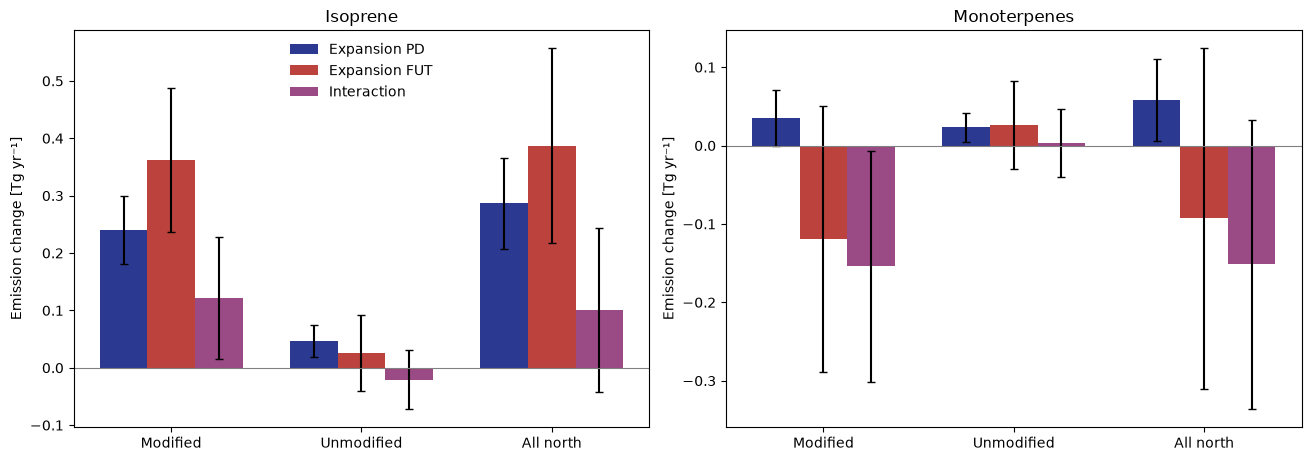

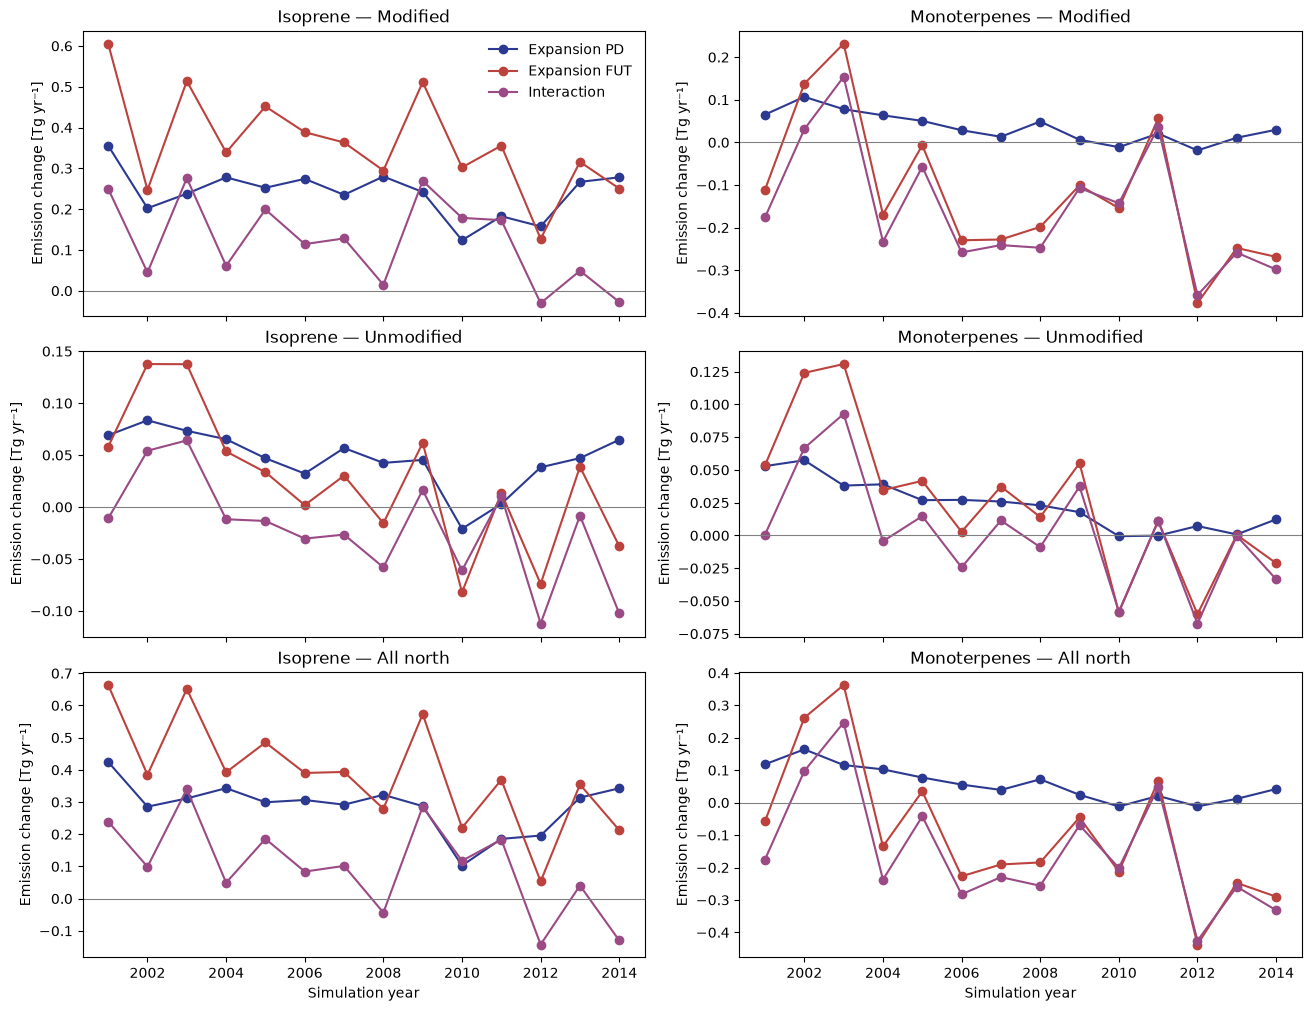

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
x, width = np.arange(len(REGIONS)), .25
for ax, var in zip(axes, VARS):
    for i, effect in enumerate(EFFECTS):
        y = annual[var].sel(effect=effect, region=REGIONS)
        ax.bar(x + (i - 1) * width, y.mean("year"), width, yerr=y.std("year", ddof=1),
               capsize=3, color=EFFECT_COLORS[effect], label=effect)
    ax.axhline(0, color="0.5", linewidth=.8)
    ax.set(title=LABELS[var], xticks=x, xticklabels=REGIONS, ylabel="Emission change [Tg yr⁻¹]")
axes[0].legend(frameon=False)
fig.savefig(OUT / "regional_expansion_interaction.png", dpi=200)
plt.show()

fig, axes = plt.subplots(3, 2, figsize=(13, 10), sharex=True, constrained_layout=True)
for i, region in enumerate(REGIONS):
    for j, var in enumerate(VARS):
        ax = axes[i, j]
        for effect in EFFECTS:
            y = annual[var].sel(region=region, effect=effect)
            ax.plot(y.year, y, "o-", label=effect, color=EFFECT_COLORS[effect])
        ax.axhline(0, color="0.5", linewidth=.8)
        ax.set(title=f"{LABELS[var]} — {region}", ylabel="Emission change [Tg yr⁻¹]")
        if i == 2:
            ax.set_xlabel("Simulation year")
axes[0, 0].legend(frameon=False)
fig.savefig(OUT / "annual_expansion_interaction.png", dpi=200)
plt.show()

## 6. Seasonal comparison
Mean fluxes use each region's own area denominator. Y-scales are shared across regions for each species. These curves can expose seasonal sign reversals hidden in annual totals.

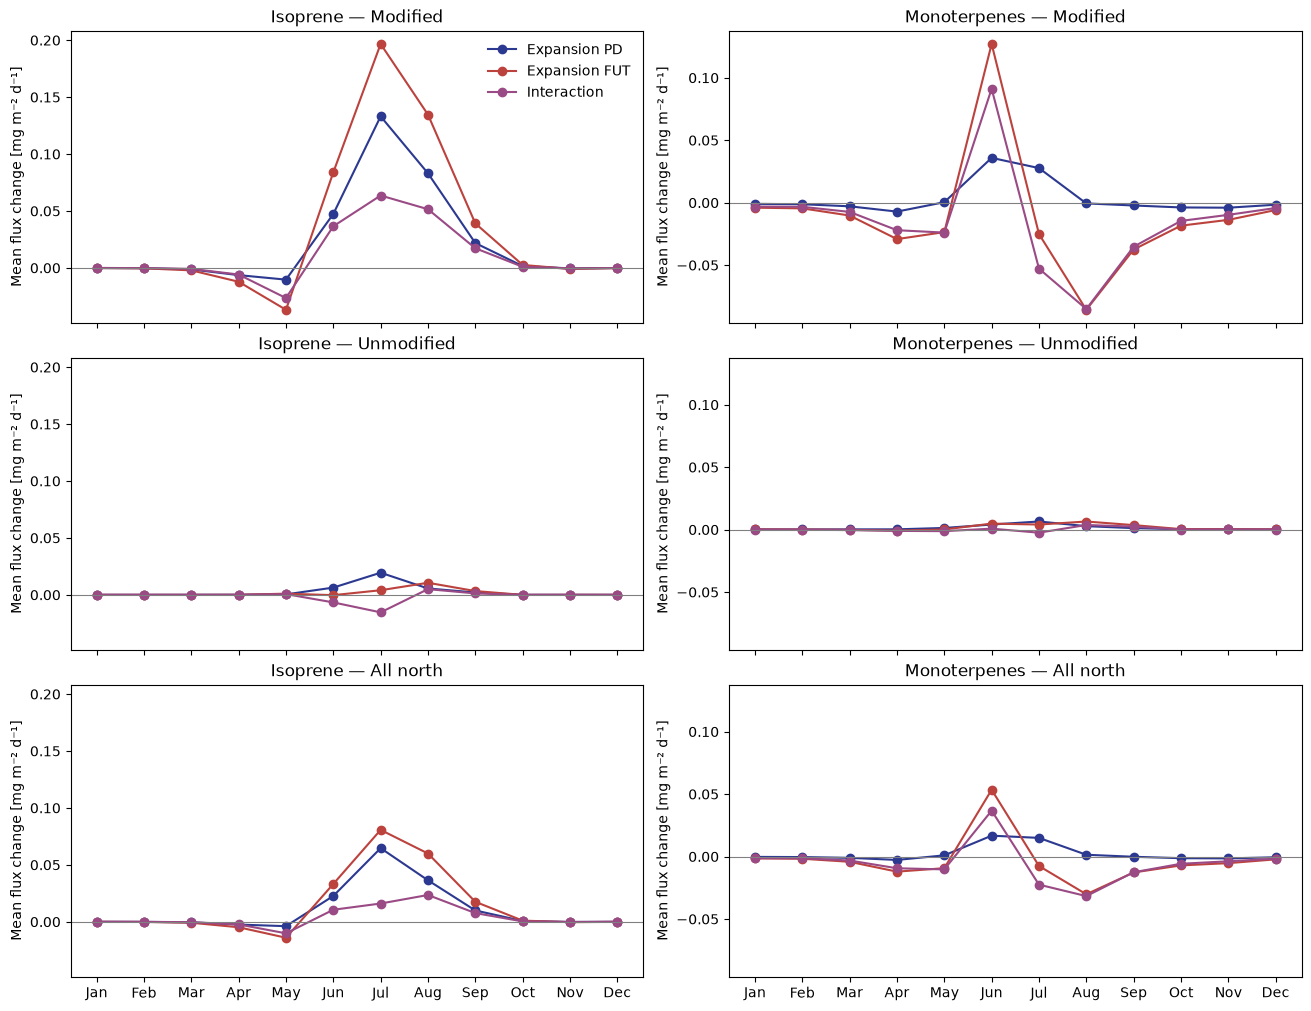

In [7]:
fig, axes = plt.subplots(3, 2, figsize=(13, 10), sharex=True, sharey="col", constrained_layout=True)
for i, region in enumerate(REGIONS):
    for j, var in enumerate(VARS):
        ax = axes[i, j]
        for effect in EFFECTS:
            y = seasonal[var].sel(region=region, effect=effect)
            ax.plot(y.month, y, "o-", label=effect, color=EFFECT_COLORS[effect])
        ax.axhline(0, color="0.5", linewidth=.8)
        ax.set(title=f"{LABELS[var]} — {region}", ylabel="Mean flux change [mg m⁻² d⁻¹]",
               xticks=range(1, 13), xticklabels=list(calendar.month_abbr)[1:])
axes[0, 0].legend(frameon=False)
fig.savefig(OUT / "seasonal_expansion_interaction.png", dpi=200)
plt.show()

## 7. Spatial cancellation
Separate positive and negative **annual-mean grid-cell** contributions. Their sum is the net budget. A small regional interaction can conceal strong opposing local interactions; this does not measure cancellation between seasons within each cell.

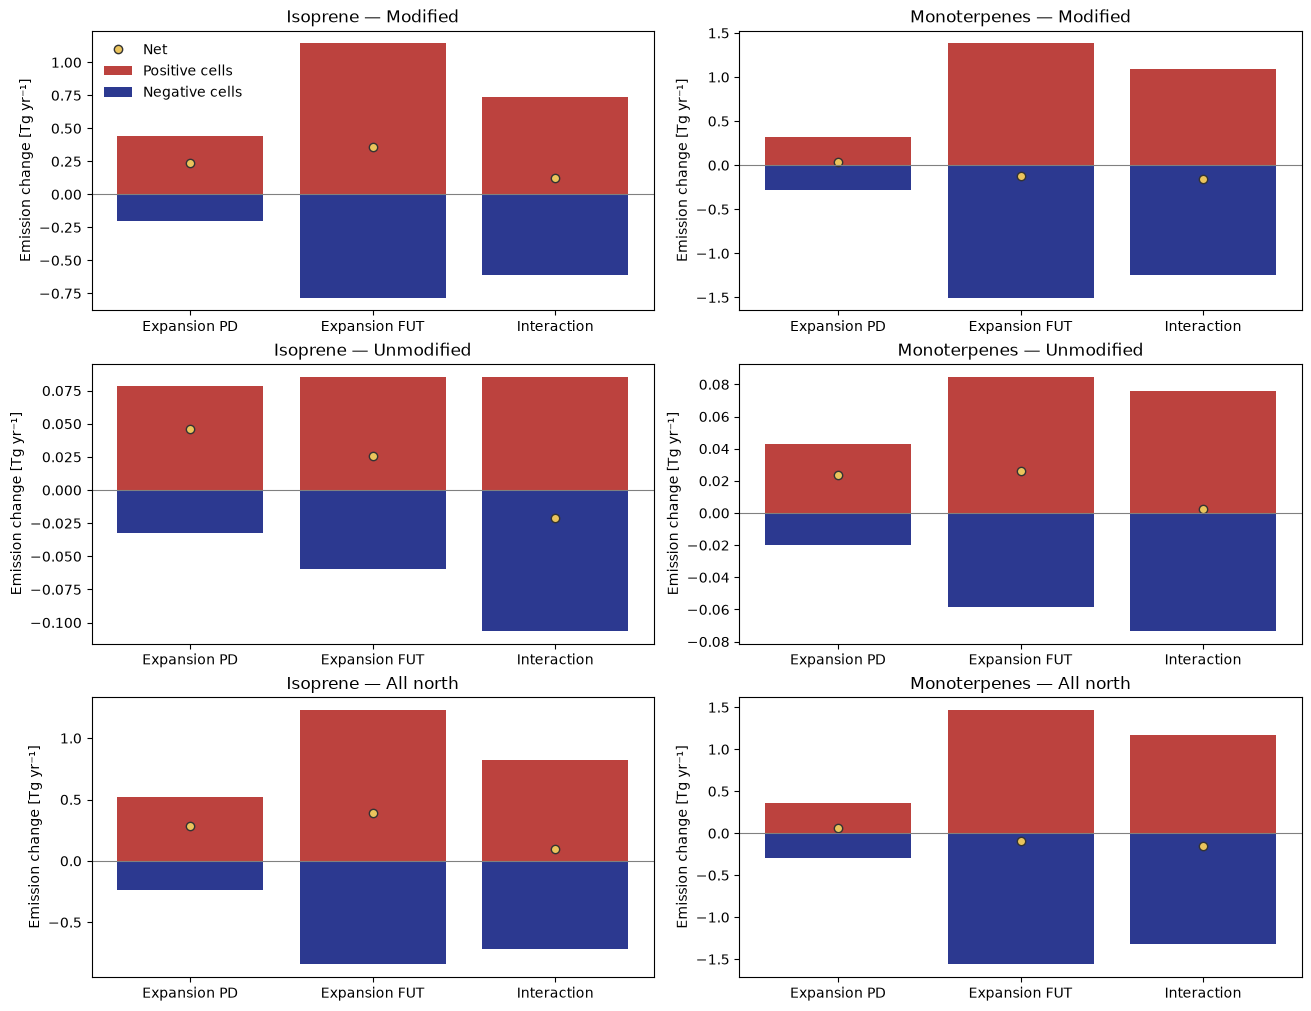

In [8]:
# Colours: project palette (src/boreal_forest_expansion/plotting/palette.py, user 2026-11-03)
cell_mean = annual_cell_mass.mean("year")
positive = (cell_mean.clip(min=0) * region_weights).sum(("lat", "lon"))
negative = (cell_mean.clip(max=0) * region_weights).sum(("lat", "lon"))
net = annual.mean("year")
xr.testing.assert_allclose(positive + negative, net)
cancellation = xr.concat([positive, negative, net], pd.Index(["Positive", "Negative", "Net"], name="component"))
cancellation.to_dataframe().to_csv(OUT / "spatial_cancellation.csv")

fig, axes = plt.subplots(3, 2, figsize=(13, 10), constrained_layout=True)
for i, region in enumerate(REGIONS):
    for j, var in enumerate(VARS):
        ax = axes[i, j]
        ax.bar(EFFECTS, positive[var].sel(region=region), color=RED, label="Positive cells")
        ax.bar(EFFECTS, negative[var].sel(region=region), color=NAVY, label="Negative cells")
        ax.plot(EFFECTS, net[var].sel(region=region), "o", color=GOLD, mec="0.2", label="Net")
        ax.axhline(0, color="0.5", linewidth=.8)
        ax.set(title=f"{LABELS[var]} — {region}", ylabel="Emission change [Tg yr⁻¹]")
axes[0, 0].legend(frameon=False)
fig.savefig(OUT / "spatial_cancellation.png", dpi=200)
plt.show()

## 8. Compare the two attribution sequences
Sequence A changes the background first, then expands vegetation.
Sequence B expands vegetation first, then changes the background.

Both sum to LCC_FUT − CTRL_PD. Their different expansion terms reflect the interaction. This check quantifies how much the emissions attribution depends on the intermediate reference; it does not measure the corresponding cloud or radiative responses.

In [9]:
path_terms = {
    "Background with control vegetation": background_ctrl,
    "Expansion in FUT": effects["Expansion FUT"],
    "Expansion in PD": effects["Expansion PD"],
    "Background with expanded vegetation": background_lcc,
}
path_flux = xr.concat(list(path_terms.values()), pd.Index(list(path_terms), name="term"))
path_annual = ((path_flux * region_weights).sum(("lat", "lon")) * seconds / 1e9).groupby("year").sum("time")
xr.testing.assert_allclose(path_annual.isel(term=0, drop=True) + path_annual.isel(term=1, drop=True),
                           path_annual.isel(term=2, drop=True) + path_annual.isel(term=3, drop=True))
path_annual.mean("year").to_dataframe().to_csv(OUT / "attribution_sequences_mean_Tg_yr.csv")
display(path_annual.mean("year").to_dataframe().round(4))

SFISOP  SFMTERP
term                                region                      
Background with control vegetation  Modified     8.3644  17.6246
                                    Unmodified   5.5004   9.2453
                                    All north   13.8648  26.8699
Expansion in FUT                    Modified     0.3619  -0.1191
                                    Unmodified   0.0255   0.0261
                                    All north    0.3874  -0.0930
Expansion in PD                     Modified     0.2404   0.0351
                                    Unmodified   0.0462   0.0234
                                    All north    0.2866   0.0585
Background with expanded vegetation Modified     8.4858  17.4704
                                    Unmodified   5.4797   9.2480
                                    All north   13.9656  26.7184

## 9. Annual and JJA maps
Rows are species; columns are Expansion PD, Expansion FUT and Interaction. Continuous `RdBu_r`, symmetric scales. With `SCALE_MODE = "grouped"` (default) Expansion PD has its own scale, Expansion FUT and Interaction share one, so they stay comparable. **Compare PD with FUT through the colourbar values, not the colours.** `SCALE_QUANTILE = 0.98` clips the 2 % most extreme cells (colourbar extensions); 1.0 uses the full range.

**Hatched = not significant:** paired t-test of the 14 yearly values in each cell (for Interaction, the yearly (LCC_FUT − CTRL_FUT) − (LCC_PD − CTRL_PD)), Benjamini–Hochberg FDR α = 0.10 over the cells ≥45°N. Dark outline = modified cells. The JJA maps use only June–August, months weighted by duration.

In [10]:
# Map style copied from plotting/forcing_maps.py (this notebook is self-contained):
# continuous RdBu_r with a symmetric scale; NON-significant cells hatched with thin grey /////
# (paired yearly t-test, Benjamini-Hochberg FDR over the cells >= MIN_LAT, alpha 0.10, Wilks 2016);
# dark outline = modified cells. All runs are nudged to the same winds, so year y pairs with year y.
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from matplotlib.colors import TwoSlopeNorm
from matplotlib.path import Path as MplPath
from matplotlib.ticker import FormatStrFormatter, MaxNLocator
from scipy import stats as sps

MAP_CMAP = "RdBu_r"
FDR_ALPHA = 0.10
CIRCLE = MplPath(np.column_stack([np.sin(np.linspace(0, 2 * np.pi, 200)),
                                  np.cos(np.linspace(0, 2 * np.pi, 200))]) * .5 + .5)
HATCH_NOTE = (f"hatched: not significant (paired yearly t-test, FDR α = {FDR_ALPHA:g} over cells ≥{MIN_LAT}°N); "
              "outline: modified cells")


def yearly_mean(field, months=None):
    """Duration-weighted yearly means (year, ..., lat, lon) of a monthly field; months e.g. [6, 7, 8]."""
    sec = seconds if months is None else seconds.where(reference.month.isin(months))
    return (field * sec).groupby("year").sum("time") / sec.groupby("year").sum("time")


def nonsignificant(yearly, within):
    """True where the yearly differences are NOT FDR-significant (only cells inside `within`)."""
    with np.errstate(invalid="ignore", divide="ignore"):
        p = sps.ttest_1samp(yearly.transpose("year", "lat", "lon").values, 0.0, axis=0,
                            nan_policy="omit").pvalue
    p = np.asarray(p)
    valid = np.isfinite(p) & within.values
    sig = np.zeros(p.shape, bool)
    ranked = np.sort(p[valid])
    below = np.nonzero(ranked <= FDR_ALPHA * np.arange(1, ranked.size + 1) / max(ranked.size, 1))[0]
    if below.size:
        sig = valid & (p <= ranked[below[-1]])
    return xr.DataArray(valid & ~sig, dims=("lat", "lon"), coords={"lat": yearly.lat, "lon": yearly.lon})


def symmetric_ticks(limit):
    """5-9 round, symmetric ticks inside +-limit (more than 5 when they fit)."""
    ticks = MaxNLocator(nbins=8, symmetric=True, steps=[1, 2, 2.5, 5, 10]).tick_values(-limit, limit)
    return ticks[np.abs(ticks) <= limit * (1 + 1e-9)]


def draw_map(ax, field, limit, nonsig=None, title=""):
    field = field.transpose("lat", "lon")
    cyclic, lon_c = add_cyclic_point(field.values, coord=field.lon.values)
    mesh = ax.pcolormesh(lon_c, field.lat, cyclic, transform=ccrs.PlateCarree(), cmap=MAP_CMAP,
                         norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit), shading="auto")
    if nonsig is not None and bool(nonsig.any()):
        data, lon_h = add_cyclic_point(nonsig.astype(float).values, coord=nonsig.lon.values)
        cs = ax.contourf(lon_h, nonsig.lat, np.where(data > .5, 1., np.nan), levels=[.5, 1.5],
                         colors="none", hatches=["/////"], transform=ccrs.PlateCarree(), zorder=4)
        cs.set_edgecolor("dimgrey")
        cs.set_linewidth(0.0)
        cs.set_hatch_linewidth(0.3)
    outline, lon_o = add_cyclic_point(modified.transpose("lat", "lon").values.astype(float),
                                      coord=modified.lon.values)
    ax.contour(lon_o, modified.lat, outline, levels=[.5], colors=["0.15"], linewidths=.5,
               transform=ccrs.PlateCarree(), zorder=5)
    ax.set_extent([-180, 180, MIN_LAT, 90], crs=ccrs.PlateCarree())
    ax.set_boundary(CIRCLE, transform=ax.transAxes)
    ax.coastlines(linewidth=.6, zorder=6)
    ax.set_title(title, fontsize=10)
    return mesh


def add_cbar(fig, axes, mesh, limit, label):
    cb = fig.colorbar(mesh, ax=axes, orientation="horizontal", shrink=.8, pad=.04, extend="both")
    cb.set_ticks(symmetric_ticks(limit))
    cb.ax.xaxis.set_major_formatter(FormatStrFormatter("%.3g"))
    cb.set_label(label)
    return cb

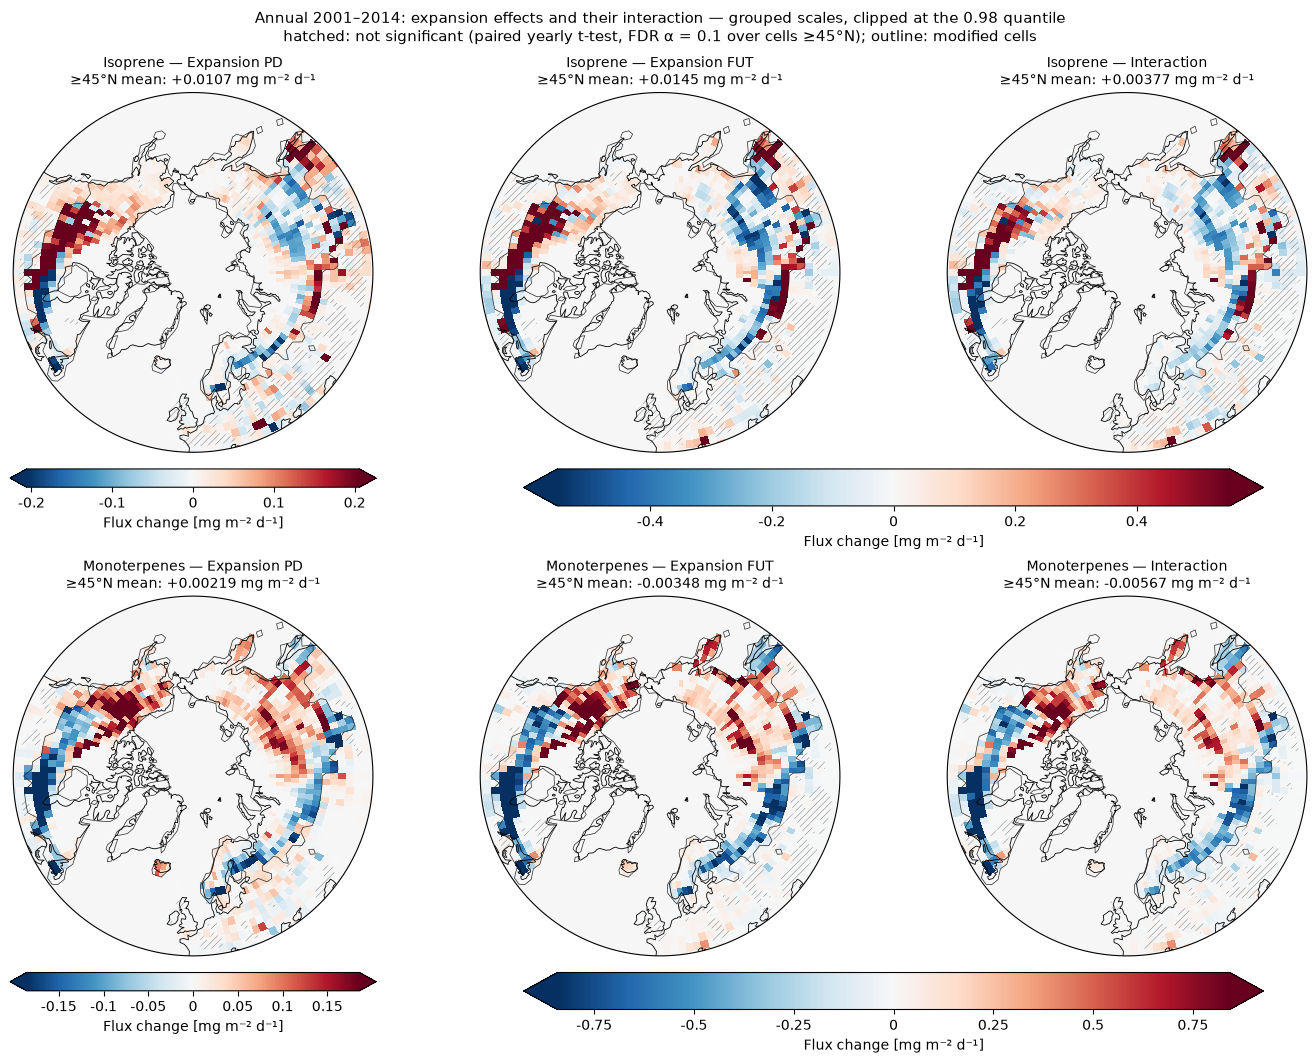

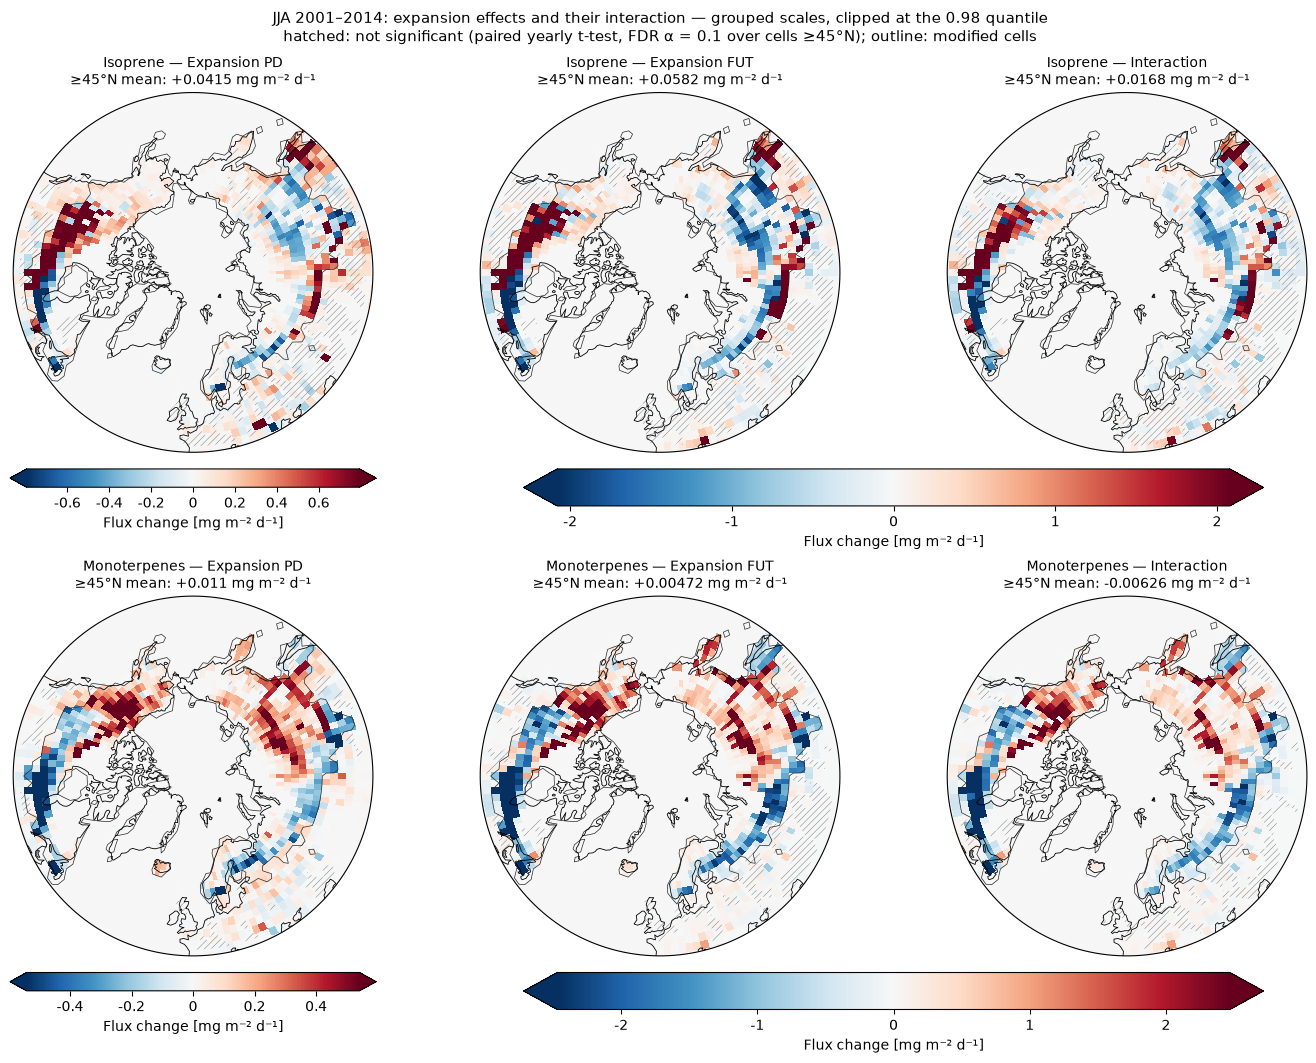

In [11]:
# "grouped": PD on its own scale, FUT and Interaction share one;
# "shared": one scale per row; "individual": one scale per panel
SCALE_MODE = "grouped"
SCALE_QUANTILE = 0.98  # 1.0 = full range; a few extreme cells otherwise wash out the maps
SCALE_GROUPS = {"grouped": [["Expansion PD"], ["Expansion FUT", "Interaction"]],
                "shared": [EFFECTS], "individual": [[e] for e in EFFECTS]}[SCALE_MODE]
w = region_weights.sel(region="All north", drop=True)

for season, months in [("Annual", None), ("JJA", [6, 7, 8])]:
    yearly = yearly_mean(flux, months) * 86400 * 1e6   # (effect, year, lat, lon), mg m-2 d-1
    mapped = yearly.mean("year")
    fig, axes = plt.subplots(2, 3, figsize=(14, 10.5),
                             subplot_kw={"projection": ccrs.NorthPolarStereo()}, constrained_layout=True)
    for row, var in enumerate(VARS):
        for group in SCALE_GROUPS:
            values = np.abs(mapped[var].sel(effect=group).where(north).values)
            limit = max(float(np.nanquantile(values, SCALE_QUANTILE)), 1e-12)
            group_axes = [axes[row, EFFECTS.index(effect)] for effect in group]
            for ax, effect in zip(group_axes, group):
                field = mapped[var].sel(effect=effect)
                avg = float((field * w).sum() / w.sum())
                mesh = draw_map(ax, field, limit, nonsignificant(yearly[var].sel(effect=effect), north),
                                f"{LABELS[var]} — {effect}\n≥{MIN_LAT}°N mean: {avg:+.3g} mg m⁻² d⁻¹")
            add_cbar(fig, group_axes, mesh, limit, "Flux change [mg m⁻² d⁻¹]")
    fig.suptitle(f"{season} {START_YEAR}–{END_YEAR}: expansion effects and their interaction — {SCALE_MODE} scales, "
                 f"clipped at the {SCALE_QUANTILE:g} quantile\n{HATCH_NOTE}", fontsize=11)
    fig.savefig(OUT / f"{season.lower()}_interaction_continuous_{SCALE_MODE}.png", dpi=200)
    plt.show()

## Interpretation checklist

- **Interaction ≈ 0:** the net expansion effect is similar in PD and FUT. Check maps and seasons for cancellation before concluding weak dependence everywhere.
- **Interaction > 0:** expansion increases emissions more, or reduces them less, in FUT.
- **Interaction < 0:** expansion reduces emissions more, or increases them less, in FUT.
- **PD and FUT effects with opposite signs:** a reversal of the net expansion-associated response.
- **Interaction concentrated outside modified cells:** investigate environmental responses and verify that the mask covers all intended imposed changes.
- **Large regional or local interaction:** strengthens the motivation for examining both attribution sequences. It does not, by itself, determine whether an additional fixed-LCC_PD atmospheric simulation is necessary.
- **Small emissions interaction:** does not imply a small atmospheric sensitivity difference; chemistry, aerosols and clouds can respond differently in PD and FUT.
- A global check may be useful later: this notebook's regional results are limited to ≥45°N.
- ISOP/MTERP only: no conclusions about other BVOC species are implied.

All CSVs and figures are saved in OUT. The notebook contains no computed scientific conclusions until run on the four simulation datasets.

## Results (2001–2014, ≥45°N, Tg yr⁻¹, mean ± interannual SD; years with + / − sign)

| Region | Species | Expansion PD | Expansion FUT | Interaction |
|---|---|---:|---:|---:|
| Modified | Isoprene | +0.24 ± 0.06 (14/0) | +0.36 ± 0.13 (14/0) | +0.12 ± 0.11 (12/2) |
| Modified | Monoterpenes | +0.04 ± 0.04 (12/2) | −0.12 ± 0.17 (3/11) | −0.15 ± 0.15 (3/11) |
| Unmodified | Isoprene | +0.05 ± 0.03 (13/1) | +0.03 ± 0.07 (10/4) | −0.02 ± 0.05 (4/10) |
| Unmodified | Monoterpenes | +0.02 ± 0.02 (12/2) | +0.03 ± 0.06 (11/3) | +0.00 ± 0.04 (7/7) |
| All north | Isoprene | +0.29 ± 0.08 (14/0) | +0.39 ± 0.17 (14/0) | +0.10 ± 0.14 (11/3) |
| All north | Monoterpenes | +0.06 ± 0.05 (12/2) | −0.09 ± 0.22 (4/10) | −0.15 ± 0.18 (3/11) |

Source: `expansion_interaction_summary.csv` (a).

- **The old-chain result is gone.** Old chain (2001–2009): expansion PD +0.43 / +0.18, FUT **−2.61 / −3.85** Tg yr⁻¹ (isoprene / monoterpenes), with 92 % / 69 % of the FUT decrease in unmodified cells. New chain: FUT isoprene **+0.39**, monoterpenes −0.09, and the unmodified cells contribute only +0.03 / +0.03. This fits the old FUT decrease being the CO₂-bug spin-up legacy (LAI loss outside the modified cells), as suspected in the old notebook (b).
- **Isoprene:** expansion raises emissions in both backgrounds (positive in all 14 years), slightly more in FUT; the interaction (+0.10 ± 0.14) is small next to its year-to-year spread.
- **Monoterpenes:** about zero in both; FUT is negative in 10 of 14 years, but the mean (−0.09) is below its SD (0.22).
- **Almost all of the effect is in the modified cells** (isoprene 0.24 of 0.29 in PD, 0.36 of 0.39 in FUT) (a).
- **Spatial cancellation is large:** in FUT, positive and negative cells give +1.23 / −0.84 (isoprene) and +1.47 / −1.56 (monoterpenes) Tg yr⁻¹ (`spatial_cancellation.csv`). The maps show the dipole: higher emissions in western Canada and eastern Siberia, lower along the southern edge of the modified area (Fennoscandia–western Russia, western Canada edge).
- **Attribution path barely matters now:** background with control vegetation +13.86 / +26.87, with expanded vegetation +13.97 / +26.72 Tg yr⁻¹ (`attribution_sequences_mean_Tg_yr.csv`). The background is ~35× (isoprene) and ~300× (monoterpenes) larger than the expansion effect.
- **Maps (§9):** many cells are significant (unhatched), even where the regional net is small: the regional means hide significant local changes of opposite sign.

Outputs: `bvoc_expansion_PD_FUT_interaction-after-co2-fix_outputs/`.